# Pair 4. Promotional clips (text-to-video)

**Business need:** short campus clips for social media and open days, without a film crew.

| | System A  | System B |
|---|---|---|
| Model | **AnimateDiff** | **Wan 2.1 T2V 1.3B** |
| How it works | A *motion module* (temporal attention layers) is plugged into a frozen Stable Diffusion 1.5 image model | A video **diffusion transformer** trained end to end on video, with flow matching and a 3D video VAE |
| Lecture link | Week 6 (spatial vs temporal attention, AnimateDiff) | Week 6 (video diffusion), Week 10 (flow matching) |
| Runs on | Laptop (slow) or lab GPU | **Lab GPU** |

Both make a clip of about 2 seconds: A = 16 frames at 8 fps, B = 33 frames at 16 fps.

In [1]:
import os, time
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
import torch

# Use the lab GPU if there is one, otherwise the Mac's GPU ("mps"), otherwise the CPU
device = "cuda" if torch.cuda.is_available() else "mps" if torch.backends.mps.is_available() else "cpu"
print("Running on:", device)

import numpy as np
import imageio.v2 as imageio

Running on: cuda


In [2]:
os.makedirs("outputs/p4/A", exist_ok=True)
os.makedirs("outputs/p4/B", exist_ok=True)
os.makedirs("results/p4", exist_ok=True)

prompts = pd.read_csv("data/p4_prompts.csv")
NEGATIVE = "blurry, low quality, distorted, text, watermark"
times_log = []
prompts

,id,prompt
0,v01,Slow camera push-in towards a modern universit...
1,v02,Aerial drone shot gliding over a green univers...
2,v03,Steam rising from a coffee cup on a desk next ...
3,v04,Time-lapse of clouds moving over a university ...
4,v05,Close-up of hands typing on a laptop keyboard ...
5,v06,Autumn leaves falling slowly onto an empty cam...


## System A: AnimateDiff

In [4]:
from diffusers import AnimateDiffPipeline, DDIMScheduler, MotionAdapter
from diffusers.utils import export_to_video

base_model = "SG161222/Realistic_Vision_V5.1_noVAE"
adapter = MotionAdapter.from_pretrained("guoyww/animatediff-motion-adapter-v1-5-2", torch_dtype=torch.float16)
pipe_A = AnimateDiffPipeline.from_pretrained(base_model, motion_adapter=adapter, torch_dtype=torch.float16)
# The scheduler settings recommended in the AnimateDiff documentation
pipe_A.scheduler = DDIMScheduler.from_pretrained(base_model, subfolder="scheduler", clip_sample=False,
                                                 timestep_spacing="linspace", beta_schedule="linear", steps_offset=1)
pipe_A = pipe_A.to(device)

times_log = []     # each system keeps and saves its own times
for _, p in prompts.iterrows():
    start = time.time()
    generator = torch.Generator("cpu").manual_seed(0)
    frames = pipe_A(p["prompt"], negative_prompt=NEGATIVE, num_frames=16, num_inference_steps=25,
                    guidance_scale=7.5, generator=generator).frames[0]
    export_to_video(frames, f"outputs/p4/A/{p['id']}.mp4", fps=8)
    times_log.append({"system": "A", "item": p["id"], "seconds": time.time() - start, "hand_minutes": 0})

pd.DataFrame(times_log).to_csv("results/p4/times_A.csv", index=False)

del pipe_A                 # free the GPU memory before loading System B
torch.cuda.empty_cache()

c:\Users\42075246\Desktop\Image Editing\.venv\Lib\site-packages\huggingface_hub\utils\_validators.py:205: UserWarning: The `local_dir_use_symlinks` argument is deprecated and ignored in `hf_hub_download`. Downloading to a local directory does not use symlinks anymore.
  warnings.warn(
The config attributes {'motion_activation_fn': 'geglu', 'motion_attention_bias': False, 'motion_cross_attention_dim': None} were passed to MotionAdapter, but are not expected and will be ignored. Please verify your config.json configuration file.
c:\Users\42075246\Desktop\Image Editing\.venv\Lib\site-packages\diffusers\utils\deprecation_utils.py:23: FutureWarning: `torch_dtype` is deprecated and will be removed in version 1.0.0. Please use `dtype` instead.
  deprecate("torch_dtype", "1.0.0", _TORCH_DTYPE_DEPRECATION_MESSAGE)
Loading pipeline components...: 100%|██████████| 5/5 [00:01<00:00,  3.88it/s]
There are modules in UNetMotionModel that should be kept in float32: []. Casting directly with `to()` can

## System B: Wan 2.1

In [5]:
from diffusers import AutoencoderKLWan, WanPipeline
 
from transformers import UMT5EncoderModel
 
model_id = "Wan-AI/Wan2.1-T2V-1.3B-Diffusers"
text_encoder = UMT5EncoderModel.from_pretrained("Wan-AI/Wan2.1-VACE-1.3B-diffusers", subfolder="text_encoder",
                                                torch_dtype=torch.bfloat16)
vae = AutoencoderKLWan.from_pretrained(model_id, subfolder="vae", torch_dtype=torch.float32)
pipe_B = WanPipeline.from_pretrained(model_id, vae=vae, text_encoder=text_encoder,
                                     torch_dtype=torch.bfloat16).to("cuda")
 
times_log = []     # each system keeps and saves its own times
for _, p in prompts.iterrows():
    start = time.time()
    generator = torch.Generator("cpu").manual_seed(0)
    frames = pipe_B(prompt=p["prompt"], negative_prompt=NEGATIVE, height=480, width=832, num_frames=33,
                    num_inference_steps=30, guidance_scale=5.0, generator=generator).frames[0]
    export_to_video(frames, f"outputs/p4/B/{p['id']}.mp4", fps=16)
    times_log.append({"system": "B", "item": p["id"], "seconds": time.time() - start, "hand_minutes": 0})
 
pd.DataFrame(times_log).to_csv("results/p4/times_B.csv", index=False)

c:\Users\42075246\Desktop\Image Editing\.venv\Lib\site-packages\huggingface_hub\file_download.py:141: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\42075246\.cache\huggingface\hub\models--Wan-AI--Wan2.1-VACE-1.3B-diffusers. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)
Loading weights: 100%|██████████| 242/242 [00:00<00:00, 5553.64it/s]
c:\Users\42075246

## Technical metrics

- **generated**: the clip exists.
- **clip_score**: average CLIP match between the prompt and 8 frames spread through the clip.
- **frame_consistency**: average CLIP similarity between each frame and the next (1 = identical). This is the *temporal consistency* problem from Week 6: flickering clips score low.
- **motion**: average pixel change between frames. A frozen clip would get a perfect consistency score, so motion is reported next to it to catch that.

In [6]:
# CLIP gives one number for "how well does this image match this text?"
# It is a proxy for quality, not a perfect judge, which is why human ratings are also collected.
from transformers import CLIPModel, CLIPProcessor

clip_model = CLIPModel.from_pretrained("openai/clip-vit-base-patch32")
clip_processor = CLIPProcessor.from_pretrained("openai/clip-vit-base-patch32")


def clip_score(image, text):
    """Similarity between an image and a text, x100. Higher = better match (typical range 15-35)."""
    inputs = clip_processor(text=[text], images=[image.convert("RGB")], return_tensors="pt", padding=True)
    with torch.no_grad():
        out = clip_model(**inputs)
    # image_embeds and text_embeds are already unit-length vectors, so the dot product is the cosine similarity
    return float((out.image_embeds[0] * out.text_embeds[0]).sum() * 100)

Loading weights: 100%|██████████| 398/398 [00:00<00:00, 56797.42it/s]


In [7]:
def read_frames(file, size=384):
    """All frames of a clip as PIL images, resized to size x size."""
    return [Image.fromarray(f).convert("RGB").resize((size, size)) for f in imageio.mimread(file, memtest=False)]


def frame_consistency(frames):
    """Average CLIP similarity between neighbouring frames (needs a dummy text for the CLIP call)."""
    inputs = clip_processor(text=["a photo"], images=frames, return_tensors="pt", padding=True)
    with torch.no_grad():
        embeddings = clip_model(**inputs).image_embeds          # one unit vector per frame
    return float((embeddings[:-1] * embeddings[1:]).sum(dim=1).mean())


def motion(frames):
    """Average absolute pixel change between neighbouring frames (0 = frozen video)."""
    grey = [np.asarray(f.convert("L"), dtype=float) / 255 for f in frames]
    return float(np.mean([np.abs(grey[i + 1] - grey[i]).mean() for i in range(len(grey) - 1)]))


rows = []
for _, p in prompts.iterrows():
    for system in ["A", "B"]:
        file = f"outputs/p4/{system}/{p['id']}.mp4"
        row = {"system": system, "item": p["id"], "generated": int(os.path.exists(file))}
        if os.path.exists(file):
            frames = read_frames(file)
            eight = [frames[i] for i in np.linspace(0, len(frames) - 1, 8).astype(int)]
            row["clip_score"] = np.mean([clip_score(f, p["prompt"]) for f in eight])
            row["frame_consistency"] = frame_consistency(frames)
            row["motion"] = motion(frames)
        rows.append(row)

metrics = pd.DataFrame(rows)
metrics.to_csv("results/p4/metrics.csv", index=False)
summary = metrics.groupby("system")[["generated", "clip_score", "frame_consistency", "motion"]].mean()
summary

,generated,clip_score,frame_consistency,motion
system,,,,
A,1.0,30.462665,0.992352,0.034693
B,1.0,29.649522,0.998337,0.003079


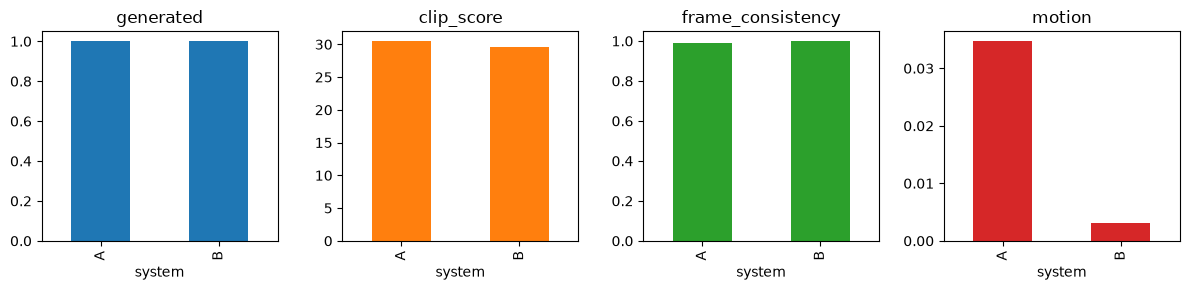

In [8]:
summary.plot(kind="bar", subplots=True, layout=(1, 4), figsize=(12, 3), legend=False)
plt.tight_layout()
plt.savefig("results/p4/metrics.png")

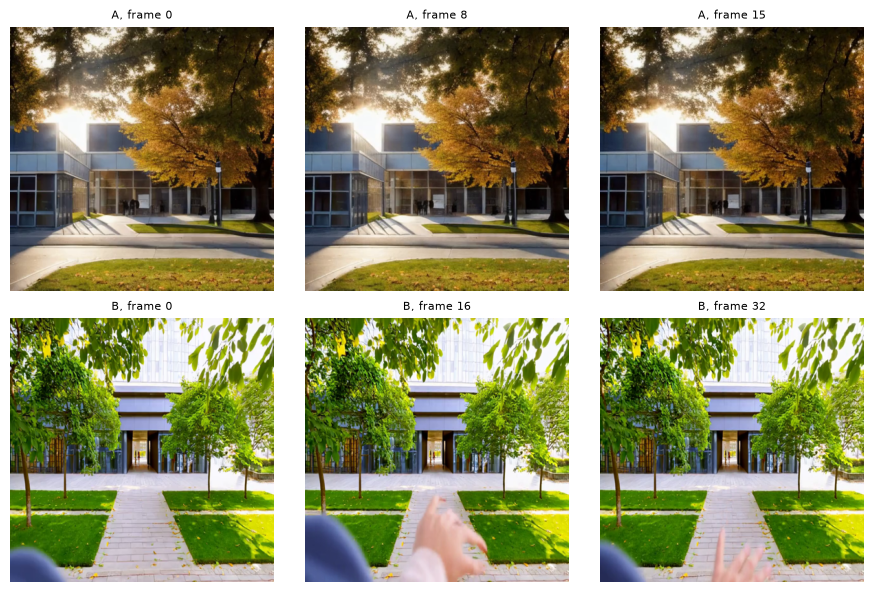

In [9]:
# First, middle and last frame of the first clip from each system
fig, axes = plt.subplots(2, 3, figsize=(9, 6))
for r, system in enumerate(["A", "B"]):
    frames = read_frames(f"outputs/p4/{system}/v01.mp4")
    for c, i in enumerate([0, len(frames) // 2, len(frames) - 1]):
        axes[r, c].imshow(frames[i])
        axes[r, c].set_title(f"{system}, frame {i}", fontsize=8)
        axes[r, c].axis("off")
plt.tight_layout()